Training Data: (13718, 113)
Test Data: (2993, 113)

Training Models...
Training Logistic Regression...


c:\Users\Yahya\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Random Forest...
Training XGBoost...


c:\Users\Yahya\anaconda3\envs\myenv\Lib\site-packages\xgboost\training.py:183: UserWarning: [00:08:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Training LightGBM...


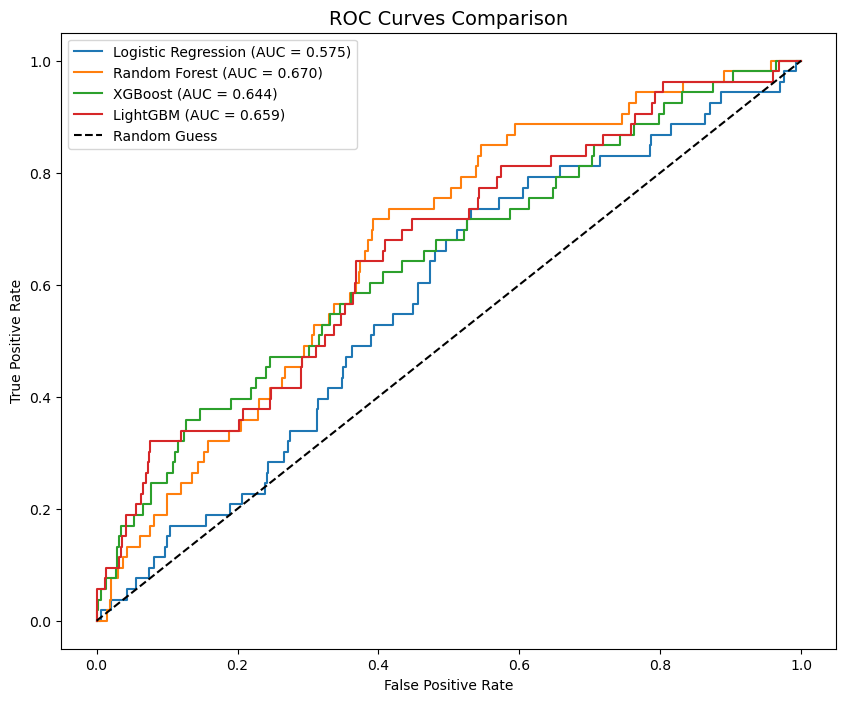


=== MODEL PERFORMANCE RANKING ===
                 Model       AUC  F1-Score    Recall  Precision
1        Random Forest  0.670017  0.000000  0.000000   0.000000
3             LightGBM  0.659113  0.035088  0.018868   0.250000
2              XGBoost  0.643852  0.034483  0.018868   0.200000
0  Logistic Regression  0.575164  0.044131  0.471698   0.023148

Success! Best model saved as 'best_model_xgboost.pkl'


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# 1. LOAD PROCESSED DATA
# load the data, saved in the previous step
X_train = pd.read_csv('../data/X_train_resampled.csv')
y_train = pd.read_csv('../data/y_train_resampled.csv').values.ravel() # .ravel() converts to 1D array
X_test = pd.read_csv('../data/X_test.csv')
y_test = pd.read_csv('../data/y_test.csv').values.ravel()

print(f"Training Data: {X_train.shape}")
print(f"Test Data: {X_test.shape}")

# 2. INITIALIZE MODELS
# set random_state for reproducibility 
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "LightGBM": LGBMClassifier(random_state=42, verbose=-1)
}

# 3. TRAIN & EVALUATE LOOP
results = []
plt.figure(figsize=(10, 8))

print("\nTraining Models...")
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    
    # Predict probabilities (for AUC) and classes (for Accuracy/F1)
    y_proba = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    
    # Calculate Metrics
    auc = roc_auc_score(y_test, y_proba)
    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred) # Crucial for Credit Risk (Catching Defaults)
    precision = precision_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "AUC": auc,
        "F1-Score": f1,
        "Recall": recall,
        "Precision": precision
    })
    
    # Plot ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

    # Save the best performing model (usually XGBoost or LightGBM) for later
    if name == "XGBoost":
        joblib.dump(model, '../models/best_model_xgboost.pkl')

# 4. VISUALIZE PERFORMANCE
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison', fontsize=14)
plt.legend()
plt.savefig('../plots/roc_curves.png')
plt.show()

# 5. DISPLAY RESULTS TABLE
results_df = pd.DataFrame(results).sort_values(by="AUC", ascending=False)
print("\n=== MODEL PERFORMANCE RANKING ===")
print(results_df)

# Save results
results_df.to_csv('../data/model_results.csv', index=False)
print("\nSuccess! Best model saved as 'best_model_xgboost.pkl'")

### Note: Persisting the Trained Model (Optional)

For this study, LightGBM is retrained from identical fixed-seed inputs (`random_state=42`) 
independently within each downstream notebook (05–08). Since the model configuration, training 
data, and seed are held constant throughout, this produces a deterministic, bit-for-bit identical 
model each time — so results remain consistent across notebooks despite the repeated training calls.

If you prefer to train once and reuse the saved model instead — e.g. for faster iteration, or to 
guard against configuration drift if hyperparameters are changed in one notebook but not another — 
the fitted model can be persisted as follows:

```python
import os
import joblib

# LightGBM selected per Chapter 5 rationale: retains sensitivity at the
# default threshold and provides the strongest foundation for threshold tuning.
best_model_name = "LightGBM"
best_model = models[best_model_name]  # already fitted in the training loop above

os.makedirs('../models', exist_ok=True)
joblib.dump(best_model, '../models/best_model_lightgbm.pkl')
print("Success! Best model saved as 'best_model_lightgbm.pkl'")
```

Downstream notebooks (05–08) could then load it directly instead of retraining:

```python
import joblib
model = joblib.load('../models/best_model_lightgbm.pkl')
```

Other models in the comparison loop can be saved the same way — replace `"LightGBM"` above with 
`"Random Forest"`, `"XGBoost"`, or `"Logistic Regression"` as needed.

**This step is not used in the current pipeline** — Notebooks 05–08 retrain LightGBM directly 
for simplicity and transparency of each notebook's dependencies.